# Max-k-SAT → EVT-оценка → углы GM-QAOA → квантовое состояние

Пошаговый эксперимент с **фиксированными аналитически подобранными углами**.
Измените параметры в первой кодовой ячейке и выполните **Restart Kernel → Run All**.
Если меняете только `DEPTH`, достаточно повторить ячейку подбора углов и последующие.
Здесь нет адаптивных обновлений и сэмплирования: распределение вычисляется точно.

**Первый запуск на локальной машине**, из корня репозитория с активным `.venv`:
```bash
python -m pip install -e ".[notebook]"
python -m jupyter lab notebooks/gm_qaoa_walkthrough.ipynb
```
В Jupyter выберите Python из этого окружения. Для VS Code также выберите `.venv`.
При необходимости зарегистрируйте kernel: `python -m ipykernel install --user --name grover-qaoa --display-name "Python (Grover QAOA)"`.


## 1. Генерируем задачу

`N_QUBITS` — число булевых переменных; `K=3` или `K=4` — размер условия.
`DENSITY` — число условий на переменную, `M=round(N_QUBITS*DENSITY)`.
Условия уникальны, переменные в условии различны, решение не «подсаживается».
Положительный литерал `i` означает $x_i$, отрицательный — $\neg x_i$.
Энергия — **число невыполненных условий**, поэтому минимизируем её.
Одинаковые параметры и `PROBLEM_SEED` воспроизводят одну формулу.


In [1]:
import os
import tempfile
from pathlib import Path

# Настройки кеша нужны, в частности, в облачной среде с read-only HOME.
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "grover-notebook-mpl"))
os.environ.setdefault("XDG_CACHE_HOME", str(Path(tempfile.gettempdir()) / "grover-notebook-cache"))

import numpy as np
import scipy
import matplotlib.pyplot as plt
from scipy.special import ndtri
from adaptive_grover_qaoa.sat import generate_clauses, sat_energies, sat_moments
from adaptive_grover_qaoa.adaptive import fit_angles, circuit_probabilities
from adaptive_grover_qaoa.core import exact_layer

%matplotlib inline

# ===== Меняйте параметры здесь =====
N_QUBITS = 10
K = 3                         # 3 или 4
DENSITY = 4.25                 # Например: 4.25 для K=3; 9.75 для K=4
PROBLEM_SEED = 3
DEPTH = 20                    # Число слоёв GM-QAOA (не число шотов)
OPTIMIZER_SEED = 3            # Отдельный seed классического подбора углов
OPTIMIZER_MAXITER = 100        # Максимум поколений DE на каждом слое
# ==================================

if K not in (3, 4):
    raise ValueError("В этом ноутбуке выберите K=3 или K=4")
if not 0 <= DEPTH or type(DEPTH) is not int:
    raise ValueError("DEPTH должен быть целым неотрицательным числом")
M = round(N_QUBITS * DENSITY)
clauses = generate_clauses(N_QUBITS, K, M, seed=PROBLEM_SEED)

print(f"Max-{K}-SAT: {N_QUBITS} переменных, {M} условий, seed={PROBLEM_SEED}")
print(f"Размер регистра: 2^{N_QUBITS} = {2**N_QUBITS:,} амплитуд")
print(f"Версии: NumPy {np.__version__}, SciPy {scipy.__version__}")
print("Первые 10 условий (OR внутри условия, AND между условиями):")
for clause in clauses[:10]:
    print("(" + " OR ".join(f"x{lit}" if lit > 0 else f"NOT x{-lit}" for lit in clause) + ")")


Max-3-SAT: 10 переменных, 42 условий, seed=3
Размер регистра: 2^10 = 1,024 амплитуд
Версии: NumPy 2.3.5, SciPy 1.17.0
Первые 10 условий (OR внутри условия, AND между условиями):
(x1 OR x2 OR x7)
(NOT x1 OR NOT x4 OR NOT x9)
(NOT x1 OR x6 OR x7)
(x4 OR x7 OR x9)
(x3 OR x4 OR NOT x7)
(NOT x1 OR NOT x8 OR NOT x10)
(NOT x1 OR NOT x7 OR x9)
(NOT x1 OR NOT x3 OR NOT x4)
(NOT x5 OR x6 OR x10)
(x2 OR x3 OR NOT x5)


## 2. Точный минимум и оценка теории экстремальных значений

Для контроля перебираем все $2^n$ присваиваний. Это экспоненциальная операция;
первый запуск лучше оставить на 8–12 кубитах, текущая реализация поддерживает до 20.

Независимо от минимума считаем моменты равномерного распределения энергии
по коэффициентам гамильтониана: $\mu=m/2^K$ и
$\sigma^2=\sum_{I\ne\emptyset}J_I^2$ после объединения одинаковых Pauli-строк.
Оценка статьи для центрированной энергии:
$E_{\mathrm{EVT}}-\mu=\sigma\Phi^{-1}(2^{-n})$.

Это **не строгая нижняя граница**. Для SAT оценка может оказаться отрицательной.
Здесь оставляем исходную оценку **без ограничения нулём**, чтобы проверить метод статьи.
Истинный минимум нужен только для контроля и не передаётся подбору углов.


In [2]:
energies = sat_energies(N_QUBITS, clauses)
exact_minimum = int(energies.min())
ground_mask = energies == exact_minimum
ground_indices = np.flatnonzero(ground_mask)
degeneracy = int(ground_mask.sum())

energy_mean, energy_sigma = sat_moments(clauses)
evt_estimate = float(energy_mean + energy_sigma * ndtri(2.0 ** (-N_QUBITS)))
centered_target = evt_estimate - energy_mean

# Проверяем формулы моментов независимым полным перебором.
np.testing.assert_allclose(energies.mean(), energy_mean, atol=1e-12)
np.testing.assert_allclose(energies.var(), energy_sigma**2, atol=1e-12)

print(f"Точный минимум энергии:        {exact_minimum}")
print(f"EVT-оценка (без обрезания):    {evt_estimate:.6f}")
print(f"Разность EVT − точный минимум: {evt_estimate - exact_minimum:+.6f}")
print(f"Средняя энергия: {energy_mean:.6f}; sigma: {energy_sigma:.6f}")
print(f"Число основных состояний: {degeneracy}")
print(f"Равномерная вероятность основного подпространства: {degeneracy / 2**N_QUBITS:.6%}")
if evt_estimate < 0:
    print("ВНИМАНИЕ: EVT-оценка вне физического диапазона E >= 0; она намеренно не исправлена.")
print("Примеры оптимальных битстрингов (x1 справа):")
for index in ground_indices[:10]:
    print(format(int(index), f"0{N_QUBITS}b"))


Точный минимум энергии:        0
EVT-оценка (без обрезания):    -0.871516
Разность EVT − точный минимум: -0.871516
Средняя энергия: 5.250000; sigma: 1.976424
Число основных состояний: 1
Равномерная вероятность основного подпространства: 0.097656%
ВНИМАНИЕ: EVT-оценка вне физического диапазона E >= 0; она намеренно не исправлена.
Примеры оптимальных битстрингов (x1 справа):
1001111010


## 3. Подбираем углы под EVT-оценку

Послойно максимизируем $|a_p(E_{\mathrm{EVT}}-\mu)|^2$ в гауссовой модели,
где $a=\sqrt{2^n}\,\psi$. Это **модельный коэффициент усиления**, не вероятность.
Углы подбираются численно по аналитической рекурсии; предыдущие слои фиксируются.
Подбор получает только моменты, целевую оценку, глубину и seed — не точный минимум.

Конвенция миксера: $H_G=2|+\rangle^{\otimes n}\langle+|^{\otimes n}$,
поэтому его фаза $e^{-2i\beta}$. Поиск: $\beta\in[0,\pi]$,
$\gamma\sigma\in[-4,4]$. `OPTIMIZER_MAXITER` задаёт бюджет, но не гарантирует
глобального оптимума. При изменении глубины повторите эту и следующие ячейки.


In [3]:
if energy_sigma > 0:
    fitted = fit_angles(
        mean=energy_mean, sigma=energy_sigma, target=evt_estimate,
        depth=DEPTH, seed=OPTIMIZER_SEED, maxiter=OPTIMIZER_MAXITER,
    )
else:
    # Константная энергия: все битстринги оптимальны, достаточно тождественной схемы.
    fitted = {"angles": [(0.0, 0.0)] * DEPTH, "nfev": 0, "target": evt_estimate}
angles = fitted["angles"]
print(f"Слоёв: {len(angles)}; вызовов целевой функции DE: {fitted['nfev']}")
print(f"{'слой':>5} {'beta':>14} {'gamma':>14} {'gamma*sigma':>14}")
for layer, (beta, gamma) in enumerate(angles, 1):
    print(f"{layer:5d} {beta:14.8f} {gamma:14.8f} {gamma*energy_sigma:14.8f}")


Слоёв: 20; вызовов целевой функции DE: 14172
 слой           beta          gamma    gamma*sigma
    1     1.80765469     0.37828476     0.74765090
    2     1.77897120     0.44960049     0.88860100
    3     1.77590575     0.45279808     0.89492079
    4     1.77722878     0.45532129     0.89990772
    5     1.77857127     0.45714874     0.90351952
    6     1.77957839     0.45838593     0.90596474
    7     1.78023865     0.45926195     0.90769612
    8     1.78079844     0.45989422     0.90894576
    9     1.78116935     0.46038120     0.90990824
   10     1.78153089     0.46076499     0.91066677
   11     1.78174690     0.46107786     0.91128513
   12     1.78199694     0.46132998     0.91178343
   13     1.78217735     0.46154403     0.91220649
   14     1.78231089     0.46172922     0.91257249
   15     1.78247188     0.46188027     0.91287103
   16     1.78255537     0.46202553     0.91315814
   17     1.78267571     0.46214344     0.91339117
   18     1.78271901     0.46225398  

## 4. Строим состояние и смотрим вероятности

Каждый слой: сначала фазовый оператор энергии, затем миксер Гровера.
Используем $E-\mu$: вычитание константы меняет лишь глобальную фазу.
Начальное состояние равномерно. Ни шума, ни конечного числа шотов здесь нет.

Слева — $|\psi(z)|^2$ для **каждого битстринга** (по его целочисленному индексу).
Красным выделены основные состояния; пунктир — начальная вероятность $2^{-n}$.
Справа — сумма вероятностей по одинаковым энергиям $P(E)$.
Вероятность получить основное состояние — сумма по **всем** вырожденным минимумам.


P(основное состояние) = 0.02370747 = 2.3707%
В равномерном состоянии: 0.0977%
Усиление вероятности оптимума: 24.276 раза
Средняя энергия после схемы: 5.231063
Нормировка состояния: 1.000000000000
Самый вероятный битстринг: 0011010001, энергия 12, вероятность 3.093165%


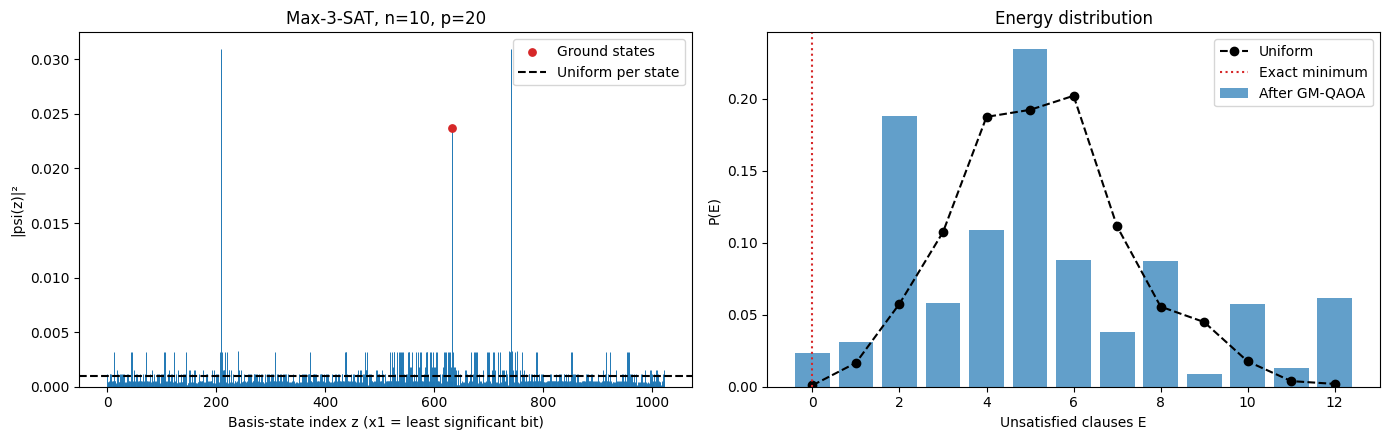

In [4]:
state = np.ones(2**N_QUBITS, dtype=complex) / np.sqrt(2**N_QUBITS)
success_by_layer = [float(np.sum(abs(state[ground_mask])**2))]
for beta, gamma in angles:
    state = exact_layer(state, energies - energy_mean, beta, gamma)
    success_by_layer.append(float(np.sum(abs(state[ground_mask])**2)))

probabilities = np.abs(state)**2
np.testing.assert_allclose(probabilities.sum(), 1.0, atol=1e-10)
np.testing.assert_allclose(
    probabilities, circuit_probabilities(energies, energy_mean, angles), atol=1e-12,
)
ground_probability = float(probabilities[ground_mask].sum())
mean_output_energy = float(probabilities @ energies)

print(f"P(основное состояние) = {ground_probability:.8f} = {ground_probability:.4%}")
print(f"В равномерном состоянии: {success_by_layer[0]:.4%}")
print(f"Усиление вероятности оптимума: {ground_probability / success_by_layer[0]:.3f} раза")
print(f"Средняя энергия после схемы: {mean_output_energy:.6f}")
print(f"Нормировка состояния: {probabilities.sum():.12f}")
most_likely = int(probabilities.argmax())
print(f"Самый вероятный битстринг: {most_likely:0{N_QUBITS}b}, "
      f"энергия {energies[most_likely]}, вероятность {probabilities[most_likely]:.6%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
indices = np.arange(len(probabilities))
axes[0].vlines(indices, 0, probabilities, color="tab:blue", linewidth=0.7)
axes[0].scatter(ground_indices, probabilities[ground_mask], color="tab:red", s=28,
                zorder=4, label="Ground states")
axes[0].axhline(1 / 2**N_QUBITS, color="black", linestyle="--", label="Uniform per state")
axes[0].set(xlabel="Basis-state index z (x1 = least significant bit)",
            ylabel="|psi(z)|²", title=f"Max-{K}-SAT, n={N_QUBITS}, p={len(angles)}")
axes[0].set_ylim(bottom=0)
axes[0].legend()

energy_axis = np.arange(int(energies.max()) + 1)
energy_probability = np.bincount(energies, weights=probabilities, minlength=len(energy_axis))
uniform_energy_probability = np.bincount(energies, minlength=len(energy_axis)) / len(energies)
axes[1].bar(energy_axis, energy_probability, alpha=0.7, label="After GM-QAOA")
axes[1].plot(energy_axis, uniform_energy_probability, "o--", color="black", label="Uniform")
axes[1].axvline(exact_minimum, color="tab:red", linestyle=":", label="Exact minimum")
axes[1].set(xlabel="Unsatisfied clauses E", ylabel="P(E)", title="Energy distribution")
axes[1].legend()
fig.tight_layout()
plt.show()


## 5. Дополнительно: что меняется с глубиной

Это вероятности для префиксов **уже найденного** расписания углов.
Для каждого слоя использовалась модельная EVT-цель; истинный минимум
не участвовал в оптимизации. Убывание истинной вероятности возможно:
монотонность модельной целевой функции не гарантирует монотонности $P(E_{min})$.


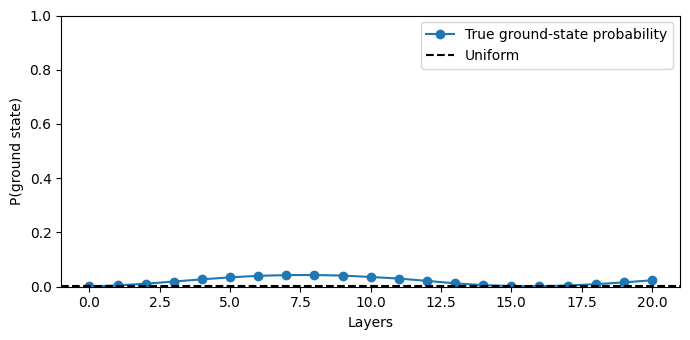

In [5]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(len(success_by_layer)), success_by_layer, "o-", label="True ground-state probability")
ax.axhline(success_by_layer[0], color="black", linestyle="--", label="Uniform")
ax.set(xlabel="Layers", ylabel="P(ground state)", ylim=(0, 1))
ax.legend()
fig.tight_layout()
plt.show()
